# EDA V2 — Altitude du sommet des nuages (CTTH) : fenêtres 11×11 MTG-FCI × EarthCARE

**But** : comprendre le jeu `data_cloud_top_V2.pkl` pour préparer un modèle **utilisable en opérationnel**
(sans correction de parallaxe calculée avec la cible) et guider le choix des méthodes spatiales
(statistiques de voisinage, filtres de Gabor, ondelettes, CNN).

Les noms de variables suivent le *Dictionnaire des variables CTTH V2* :
grandeur → canal ou niveau → opération → support (`win11` fenêtre brute, `p5raw` vignette brute 5×5,
`p5corr` vignette corrigée avec la cible = **interdite en opérationnel**).

| Section | Question |
|---|---|
| 1. Chargement et nommage | Renommer, typer, construire le cube `bt_win11` (N, 6, 11, 11) |
| 2. Qualité | Valeurs manquantes, valeur de remplissage, type 10, lien avec la V1 |
| 3. Couverture et cible | Répartition dans le temps, distribution de l'altitude |
| 4. Parallaxe et position du nuage | Où se trouve le nuage dans la fenêtre selon son altitude ? |
| 5. Structure spatiale | Quelles échelles, textures et orientations distinguent les nuages ? (prépare Gabor, ondelettes, CNN) |
| 6. Variables physiques | Contrastes entre canaux et avec le ciel clair, inversion ERA5 |
| 7. Valeur informative | Que rapporte chaque famille de variables, en validation croisée par jour ? |
| 8. Diagnostic SAFNWC | Où la référence se trompe-t-elle ? |
| 9. Synthèse | Conséquences pour la modélisation |

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import pywt

pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10})

DATA_PATH = './Data/data_cloud_top_V2.pkl'      # adapter si besoin
raw = pd.read_pickle(DATA_PATH).reset_index(drop=True)
print(raw.shape)

(87746, 45)


In [19]:
### !pip install PyWavelets lightgbm

## 1. Chargement, nommage explicite et cube de fenêtres

In [20]:
CH_ORIG = ['WV_063', 'WV_073', 'IR_087', 'IR_105', 'IR_123', 'IR_133']
CH = ['wv063', 'wv073', 'ir087', 'ir105', 'ir123', 'ir133']
P_LEVELS = [1000, 850, 700, 500, 300, 200, 100]
SAF_FILL = 63535

rename = {}
for o, c in zip(CH_ORIG, CH):
    rename[o + '_ClearSky'] = f'bt_{c}_clearsky'
    rename[o + '_C5'] = f'bt_{c}_min_p5corr'
    rename[o + '_W5'] = f'bt_{c}_max_p5corr'
    rename[o + '_std5'] = f'bt_{c}_std_p5corr'
rename |= {f'T_{p}': f't_era5_{p}hpa' for p in P_LEVELS}
rename |= {'nb_pix_LON_cor_parallax': 'parallax_shift_lon_px', 'nb_pix_LAT_cor_parallax': 'parallax_shift_lat_px',
           'Cloud_Top_Altitude_EarthCARE': 'cth_earthcare_m', 'Cloud_Top_Altitude_SAFNWC': 'cth_safnwc_m',
           'Cloud_Type_SAFNWC': 'cloud_type_safnwc', 'Day_UTC': 'date_utc', 'HH_UTC': 'hour_utc', 'MN_UTC': 'minute_utc'}

df = raw.drop(columns=CH_ORIG).rename(columns=rename)

# Types explicites (certaines colonnes sont des scalaires rangés en "object")
df['date_utc'] = df['date_utc'].astype(int)
for c in CH:
    df[f'bt_{c}_clearsky'] = df[f'bt_{c}_clearsky'].astype(float)
df['cth_safnwc_m'] = df['cth_safnwc_m'].astype(float).where(df['cth_safnwc_m'] != SAF_FILL)   # 63535 -> NaN

# Cube des fenêtres brutes : (N, 6 canaux, 11 lignes = longitude, 11 colonnes = latitude)
bt_win11 = np.stack([np.stack(raw[o].values) for o in CH_ORIG], axis=1).astype('float32')
del raw
print('bt_win11 :', bt_win11.shape, f'{bt_win11.nbytes/1e6:.0f} Mo')
df.head(3).T.head(20)

bt_win11 : (87746, 6, 11, 11) 255 Mo


,0,1,2
cloud_type_safnwc,12.000000,11.000000,14.000000
bt_wv073_clearsky,255.355759,255.357040,255.358276
bt_wv073_max_p5corr,255.259995,255.259995,255.259995
bt_ir123_max_p5corr,281.959991,282.000000,282.000000
bt_wv063_max_p5corr,235.599991,235.599991,235.599991
bt_ir087_min_p5corr,270.320007,270.320007,270.440002
bt_wv073_std_p5corr,0.340784,0.378986,0.428280
parallax_shift_lon_px,2.000000,2.000000,2.000000
parallax_shift_lat_px,0.000000,0.000000,0.000000
bt_ir133_min_p5corr,260.040009,260.040009,259.449982


In [21]:
CT_NAMES = {5: 'Very low', 6: 'Low', 7: 'Mid-level', 8: 'High', 9: 'Very high', 10: 'Fractional',
            11: 'Semitransp. thin', 12: 'Semitransp. mod. thick', 13: 'Semitransp. thick',
            14: 'Semitransp. above low/mid'}
TARGET, SAF, CT = 'cth_earthcare_m', 'cth_safnwc_m', 'cloud_type_safnwc'
y = df[TARGET].values
N = len(df); k = np.arange(N)
IR105 = CH.index('ir105')

dates = sorted(df['date_utc'].unique())
df['split'] = df['date_utc'].map({d: 'train' for d in dates[:11]} | {dates[11]: 'validation', dates[12]: 'test'})

ALT_BINS = [0, 2000, 4000, 6000, 8000, 10000, 12000, 14000, 17000]
df['alt_bin'] = pd.cut(df[TARGET], ALT_BINS)

def metrics(y_true, y_pred):
    m = ~np.isnan(y_pred)
    e = y_pred[m] - y_true[m]
    return pd.Series({'N': m.sum(), 'MAE': np.abs(e).mean(), 'Biais': e.mean(), 'RMSE': np.sqrt((e**2).mean()),
                      'R2': 1 - (e**2).sum() / ((y_true[m] - y_true[m].mean())**2).sum()})

## 2. Qualité des données

In [22]:
print('Valeurs manquantes dans les fenêtres :', int(np.isnan(bt_win11).sum()))
num = df.select_dtypes('number')
print('Valeurs manquantes (colonnes scalaires, hors SAFNWC) :', int(num.drop(columns=[SAF]).isna().sum().sum()))
print('Doublons exacts (colonnes scalaires) :', int(num.duplicated().sum()))
print(f"Altitude SAFNWC absente (63535 -> NaN) : {df[SAF].isna().sum()} lignes")
pd.crosstab(df[CT].map(lambda c: f'{c} {CT_NAMES[c]}'), df[SAF].isna(), margins=True).rename(columns={False: 'SAFNWC présent', True: 'SAFNWC absent'})

Valeurs manquantes dans les fenêtres : 0
Valeurs manquantes (colonnes scalaires, hors SAFNWC) : 0
Doublons exacts (colonnes scalaires) : 2
Altitude SAFNWC absente (63535 -> NaN) : 8313 lignes


cth_safnwc_m,SAFNWC présent,SAFNWC absent,All
cloud_type_safnwc,,,
10 Fractional,0,8313,8313
11 Semitransp. thin,4197,0,4197
12 Semitransp. mod. thick,8249,0,8249
13 Semitransp. thick,1755,0,1755
14 Semitransp. above low/mid,3258,0,3258
5 Very low,30694,0,30694
6 Low,16278,0,16278
7 Mid-level,8113,0,8113
8 High,6072,0,6072


In [23]:
# Les statistiques _p5corr sont-elles bien calculées sur la vignette corrigée ? (convention : axe 0 = longitude)
i0 = 5 + df['parallax_shift_lon_px'].values
j0 = 5 + df['parallax_shift_lat_px'].values
def patch5(ch, ci, cj):
    w = bt_win11[:, ch]
    return np.stack([w[k, ci + di, cj + dj] for di in range(-2, 3) for dj in range(-2, 3)], axis=1)

p5c = patch5(IR105, i0, j0)
p5r = bt_win11[:, IR105, 3:8, 3:8].reshape(N, 25)
print('min(p5corr) == bt_ir105_min_p5corr :', np.mean(np.isclose(p5c.min(1), df['bt_ir105_min_p5corr'])).round(4))
print('min(p5raw)  == bt_ir105_min_p5corr :', np.mean(np.isclose(p5r.min(1), df['bt_ir105_min_p5corr'])).round(4))

min(p5corr) == bt_ir105_min_p5corr : 1.0
min(p5raw)  == bt_ir105_min_p5corr : 0.4268


**À retenir**
- Aucune valeur manquante dans les fenêtres ; 63 535 m est une **valeur de remplissage** du SAFNWC, présente exactement sur les **8 313 nuages fractionnés (type 10)**. Elle est convertie en NaN.
- Les colonnes `_p5corr` sont bien calculées sur la vignette **corrigée avec la cible** (100 % de concordance), pas sur la vignette brute : elles sont **interdites** dans le scénario opérationnel.
- Convention confirmée : axe 0 de la fenêtre = longitude, axe 1 = latitude.

## 3. Couverture temporelle et cible

date_utc,20250613,20250614,20250615,20250616,20250618,20250619,20250620,20250621,20250622,20250627,20250628,20250629,20250630
n,3816,8525,7307,4962,7779,7943,6323,5969,3295,8225,8283,6979,8340
split,train,train,train,train,train,train,train,train,train,train,train,validation,test
type10,341,855,1017,572,682,597,577,674,257,685,730,602,724
pct,4.3,9.7,8.3,5.7,8.9,9.1,7.2,6.8,3.8,9.4,9.4,8.0,9.5


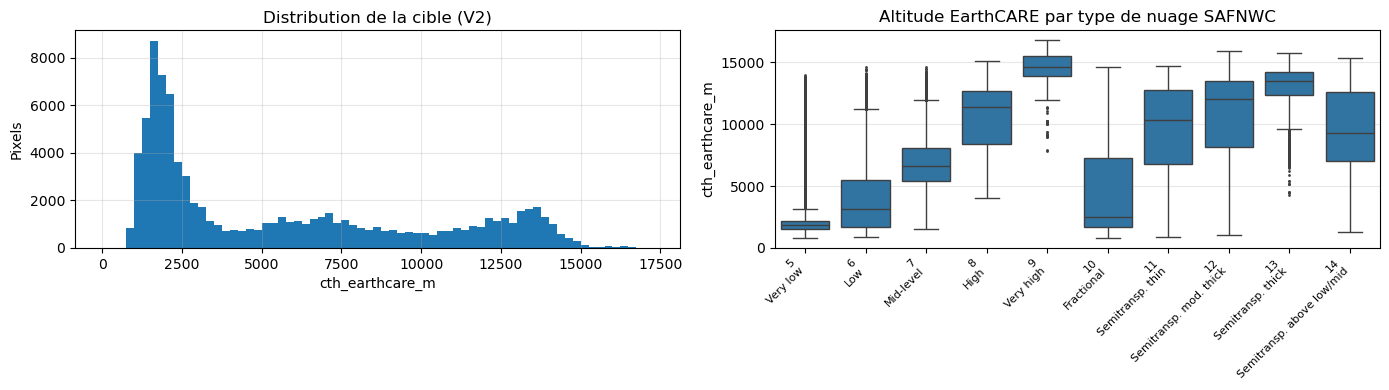

,n,nom,pct,cth médiane (m)
cloud_type_safnwc,,,,
5,30694,Very low,35.0,1833.333374
6,16278,Low,18.6,3100.000000
7,8113,Mid-level,9.2,6650.000000
8,6072,High,6.9,11400.000000
9,817,Very high,0.9,14600.000000
10,8313,Fractional,9.5,2500.000000
11,4197,Semitransp. thin,4.8,10366.666992
12,8249,Semitransp. mod. thick,9.4,12050.000000
13,1755,Semitransp. thick,2.0,13500.000000


In [24]:
per_day = df.groupby('date_utc').agg(n=(TARGET, 'size'), split=('split', 'first'), type10=(CT, lambda s: (s == 10).sum()))
per_day['pct'] = (100 * per_day['n'] / N).round(1)
display(per_day.T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(y, bins=np.arange(0, 17500, 250), color='C0')
axes[0].set_xlabel('cth_earthcare_m'); axes[0].set_ylabel('Pixels'); axes[0].set_title('Distribution de la cible (V2)')
order = sorted(df[CT].unique())
sns.boxplot(data=df, x=CT, y=TARGET, order=order, ax=axes[1], color='C0', fliersize=1)
axes[1].set_xticks(range(len(order)), [f'{o}\n{CT_NAMES[o]}' for o in order], rotation=45, ha='right', fontsize=8)
axes[1].set_xlabel(''); axes[1].set_title('Altitude EarthCARE par type de nuage SAFNWC')
plt.tight_layout(); plt.show()

ct_tab = df[CT].value_counts().sort_index().to_frame('n')
ct_tab['nom'] = ct_tab.index.map(CT_NAMES); ct_tab['pct'] = (100 * ct_tab['n'] / N).round(1)
ct_tab['cth médiane (m)'] = df.groupby(CT)[TARGET].median()
ct_tab

**À retenir**
- 13 jours de juin 2025, 87 746 pixels ; train / validation / test = 11 / 1 / 1 jours.
- Les nuages **fractionnés (type 10)**, nouveaux dans la V2, sont surtout bas ou moyens et n'ont pas d'altitude SAFNWC : on peut les garder pour l'apprentissage, mais pas pour la comparaison avec le SAFNWC.
- Distribution toujours bimodale (nuages bas vers 2 km, nuages hauts vers 13 km).

## 4. Parallaxe et position du nuage dans la fenêtre

En scénario opérationnel, le modèle reçoit la fenêtre centrée sur le pixel au sol. Le « bon » pixel
(vu par EarthCARE) est décalé de `parallax_shift_*` pixels, d'autant plus que le nuage est haut.

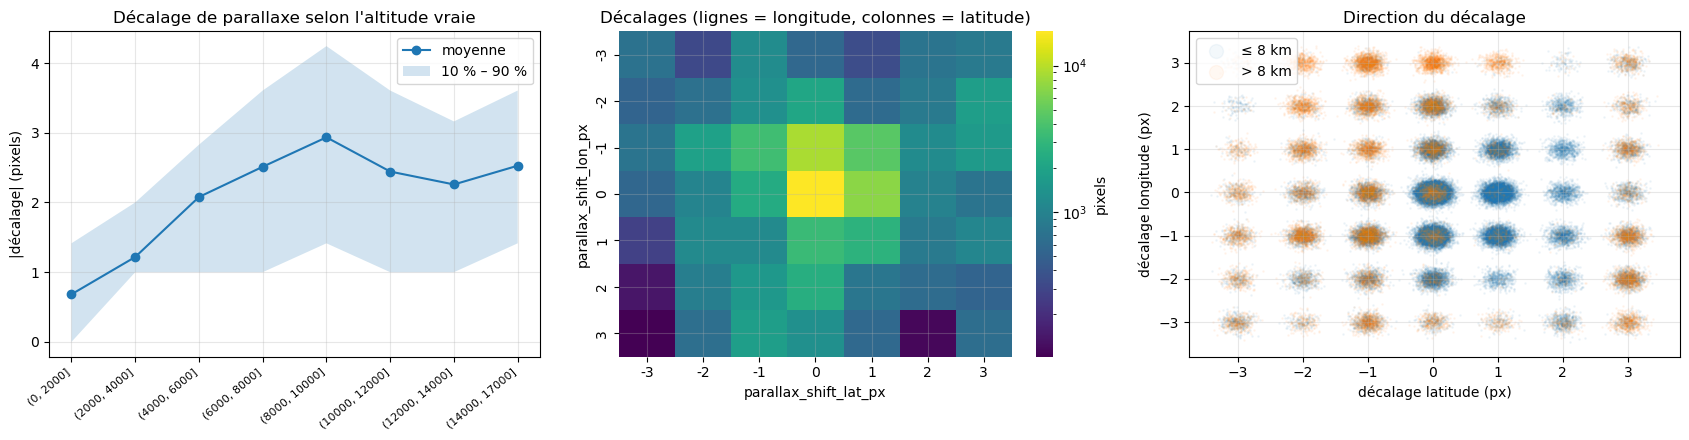

Corrélation |décalage| / altitude : 0.582


In [25]:
shift = np.hypot(df['parallax_shift_lon_px'], df['parallax_shift_lat_px'])
df['parallax_shift_norm_px'] = shift

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
g = df.groupby('alt_bin', observed=True)['parallax_shift_norm_px']
axes[0].plot(range(len(g)), g.mean(), 'o-', label='moyenne')
axes[0].fill_between(range(len(g)), g.quantile(.1), g.quantile(.9), alpha=.2, label='10 % – 90 %')
axes[0].set_xticks(range(len(g)), [str(b) for b in g.mean().index], rotation=40, ha='right', fontsize=8)
axes[0].set_ylabel('|décalage| (pixels)'); axes[0].set_title("Décalage de parallaxe selon l'altitude vraie"); axes[0].legend()

H = pd.crosstab(df['parallax_shift_lon_px'], df['parallax_shift_lat_px'])
sns.heatmap(H, ax=axes[1], cmap='viridis', norm=mpl.colors.LogNorm(), cbar_kws={'label': 'pixels'})
axes[1].set_title('Décalages (lignes = longitude, colonnes = latitude)')

hi = df[TARGET] > 8000
for m, lab in [(~hi, '≤ 8 km'), (hi, '> 8 km')]:
    axes[2].scatter(df.loc[m, 'parallax_shift_lat_px'] + np.random.normal(0, .12, m.sum()),
                    df.loc[m, 'parallax_shift_lon_px'] + np.random.normal(0, .12, m.sum()), s=1, alpha=.05, label=lab)
axes[2].set_xlabel('décalage latitude (px)'); axes[2].set_ylabel('décalage longitude (px)')
axes[2].set_title('Direction du décalage'); axes[2].legend(markerscale=10)
plt.tight_layout(); plt.show()
print(f"Corrélation |décalage| / altitude : {np.corrcoef(shift, y)[0,1]:.3f}")

|bt_ir105 corrigé − bt_ir105 au sol| moyen (K) par tranche d'altitude :


,"(0, 2000]","(2000, 4000]","(4000, 6000]","(6000, 8000]","(8000, 10000]","(10000, 12000]","(12000, 14000]","(14000, 17000]"
K,0.58,1.51,2.78,4.58,5.26,4.84,4.1,3.9


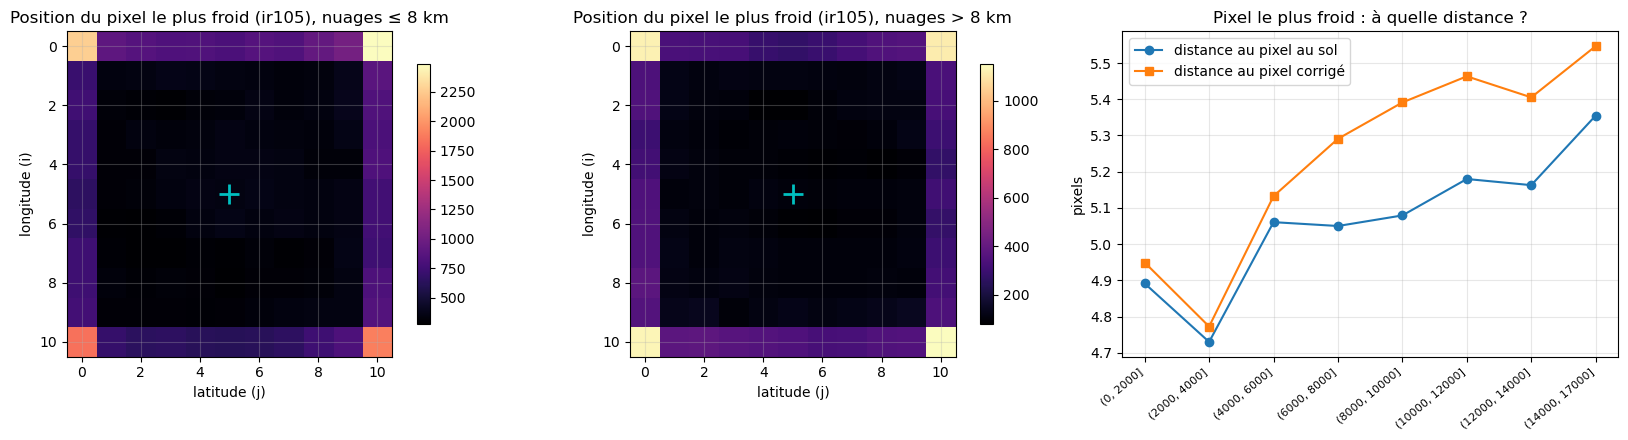

In [26]:
# Écart entre le pixel au sol et le pixel corrigé
bt_center_raw = bt_win11[:, IR105, 5, 5]
bt_center_corr = bt_win11[k, IR105, i0, j0]
d = pd.Series(np.abs(bt_center_corr - bt_center_raw)).groupby(df['alt_bin'].values, observed=True)
print("|bt_ir105 corrigé − bt_ir105 au sol| moyen (K) par tranche d'altitude :")
display(d.mean().round(2).to_frame('K').T)

# Où est le pixel le plus froid de la fenêtre 11x11 ?
w = bt_win11[:, IR105].reshape(N, 121)
amin = w.argmin(1); ai, aj = amin // 11, amin % 11
df['coldest_dist_px'] = np.hypot(ai - 5, aj - 5)
df['coldest_to_corr_px'] = np.hypot(ai - i0, aj - j0)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (m, lab) in zip(axes[:2], [(~hi, 'nuages ≤ 8 km'), (hi, 'nuages > 8 km')]):
    pos = np.bincount(amin[m.values], minlength=121).reshape(11, 11)
    im = ax.imshow(pos, cmap='magma'); plt.colorbar(im, ax=ax, shrink=.8)
    ax.plot(5, 5, 'c+', ms=14, mew=2)
    ax.set_title(f'Position du pixel le plus froid (ir105), {lab}'); ax.set_xlabel('latitude (j)'); ax.set_ylabel('longitude (i)')
g = df.groupby('alt_bin', observed=True)
axes[2].plot(range(len(g)), g['coldest_dist_px'].mean(), 'o-', label='distance au pixel au sol')
axes[2].plot(range(len(g)), g['coldest_to_corr_px'].mean(), 's-', label='distance au pixel corrigé')
axes[2].set_xticks(range(len(g)), [str(b) for b in g.mean(numeric_only=True).index], rotation=40, ha='right', fontsize=8)
axes[2].set_ylabel('pixels'); axes[2].set_title('Pixel le plus froid : à quelle distance ?'); axes[2].legend()
plt.tight_layout(); plt.show()

**À retenir**
- Le décalage de parallaxe croît avec l'altitude (corrélation ≈ 0,58) et atteint **2 à 3 pixels en moyenne au-dessus de 5 km** (contre 0,7 sous 2 km), avec un maximum de 3 pixels (limite de la fenêtre corrigée).
- Il a une **direction privilégiée** (géométrie de visée de MTG sur la zone) : l'augmentation de données par rotation ou retournement d'un CNN n'est donc pas neutre.
- Pour les nuages hauts, le pixel au sol diffère du pixel corrigé de 4 à 5 K en moyenne (entre 6 et 12 km) : c'est l'information que le modèle opérationnel doit aller chercher dans le voisinage.
- Le **pixel le plus froid de la 11×11 est presque toujours sur un bord ou un coin** (distance moyenne ≈ 5 pixels du centre, quelle que soit l'altitude). Le nuage déborde de la fenêtre et le champ est dominé par un **gradient à grande échelle** : la position du minimum ne localise pas le nuage visé, et `min_win11` mesure surtout ce qui se passe au bord.
- Conséquence : pour les textures (Gabor, ondelettes), il faudra **retirer ce gradient** (soustraire un plan ajusté) avant l'analyse, sinon les filtres ne verront que lui.

## 5. Structure spatiale : échelles, textures, orientations

Ces analyses préparent directement les méthodes spatiales :
- **variance selon la taille de fenêtre** → quelle taille de voisinage est utile ;
- **spectre de puissance radial** → quelles échelles (fréquences) choisir pour Gabor ;
- **anisotropie** → l'orientation compte-t-elle (Gabor orienté ou moyenné) ;
- **énergie des ondelettes par niveau** → combien de niveaux exploiter.

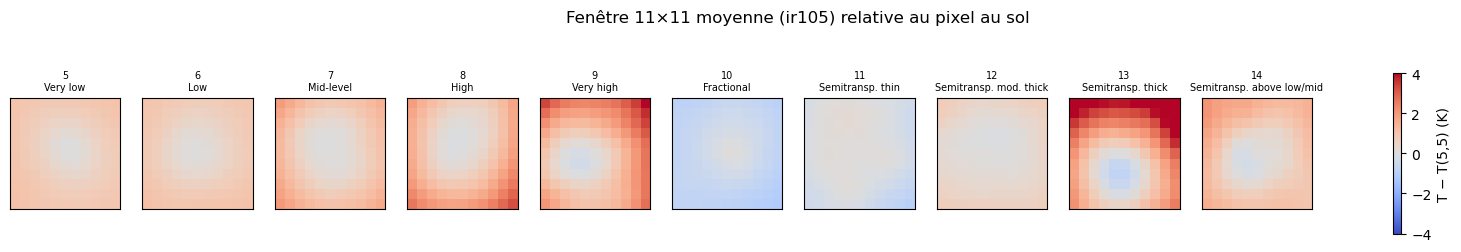

In [27]:
cts = sorted(df[CT].unique())
w105 = bt_win11[:, IR105]

# Fenêtre moyenne relative au pixel au sol, par type
fig, axes = plt.subplots(1, len(cts), figsize=(2.1 * len(cts), 2.6))
for ax, ct in zip(axes, cts):
    m = (df[CT] == ct).values
    im = ax.imshow((w105[m] - w105[m, 5:6, 5:6]).mean(0), cmap='coolwarm', vmin=-4, vmax=4)
    ax.set_title(f'{ct}\n{CT_NAMES[ct]}', fontsize=7); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=.8, label='T − T(5,5) (K)')
fig.suptitle('Fenêtre 11×11 moyenne (ir105) relative au pixel au sol', y=1.05); plt.show()

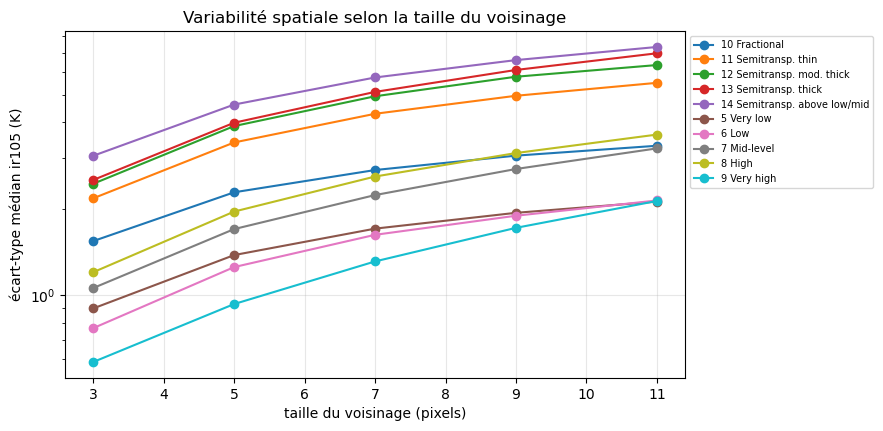

taille,3,5,7,9,11
type,,,,,
10 Fractional,1.54,2.28,2.73,3.06,3.32
11 Semitransp. thin,2.18,3.41,4.29,4.95,5.49
12 Semitransp. mod. thick,2.45,3.88,4.93,5.77,6.34
13 Semitransp. thick,2.52,3.99,5.11,6.09,6.96
14 Semitransp. above low/mid,3.06,4.62,5.73,6.59,7.32
5 Very low,0.90,1.38,1.71,1.94,2.12
6 Low,0.77,1.25,1.62,1.89,2.14
7 Mid-level,1.06,1.70,2.23,2.75,3.25
8 High,1.20,1.96,2.59,3.13,3.63


In [28]:
# Variabilité selon la taille du voisinage
sizes = [3, 5, 7, 9, 11]
rows = []
for s in sizes:
    h = s // 2
    sd = w105[:, 5-h:6+h, 5-h:6+h].reshape(N, -1).std(1)
    for ct in cts:
        rows.append({'taille': s, 'type': f'{ct} {CT_NAMES[ct]}', 'std médian (K)': np.median(sd[(df[CT] == ct).values])})
var_scale = pd.DataFrame(rows).pivot(index='type', columns='taille', values='std médian (K)')
plt.figure(figsize=(8, 4.5))
for t, r in var_scale.iterrows(): plt.plot(sizes, r.values, 'o-', label=t)
plt.xlabel('taille du voisinage (pixels)'); plt.ylabel('écart-type médian ir105 (K)'); plt.yscale('log')
plt.title('Variabilité spatiale selon la taille du voisinage'); plt.legend(fontsize=7, bbox_to_anchor=(1, 1)); plt.show()
var_scale.round(2)

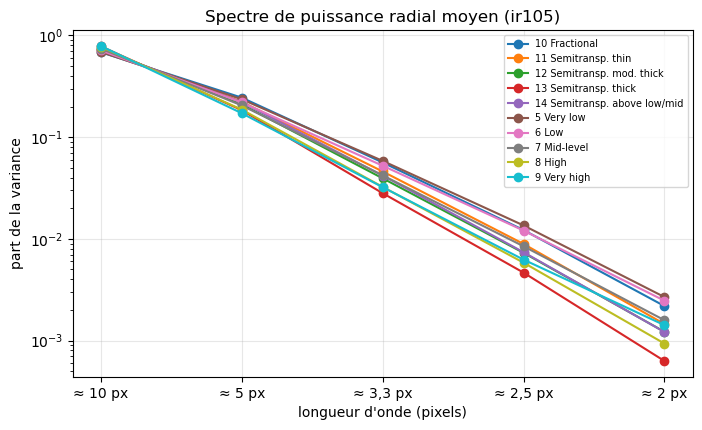

,≈ 10 px,≈ 5 px,"≈ 3,3 px","≈ 2,5 px",≈ 2 px
10 Fractional,0.685,0.245,0.056,0.012,0.002
11 Semitransp. thin,0.721,0.223,0.046,0.009,0.001
12 Semitransp. mod. thick,0.742,0.210,0.039,0.007,0.001
13 Semitransp. thick,0.782,0.184,0.028,0.005,0.001
14 Semitransp. above low/mid,0.729,0.220,0.042,0.007,0.001
5 Very low,0.689,0.236,0.058,0.014,0.003
6 Low,0.714,0.219,0.052,0.012,0.002
7 Mid-level,0.743,0.205,0.042,0.008,0.002
8 High,0.774,0.187,0.032,0.006,0.001
9 Very high,0.788,0.172,0.032,0.006,0.001


In [29]:
# Spectre de puissance radial (FFT 2D, fenêtre de Hann pour limiter les effets de bord)
hann = np.outer(np.hanning(11), np.hanning(11))
fx = np.fft.fftfreq(11)
fr = np.hypot(*np.meshgrid(fx, fx, indexing='ij'))
rbins = np.array([0.05, 0.15, 0.25, 0.35, 0.45, 0.71])
rlab = ['≈ 10 px', '≈ 5 px', '≈ 3,3 px', '≈ 2,5 px', '≈ 2 px']

def radial_spectrum(win):
    a = (win - win.mean((1, 2), keepdims=True)) * hann
    P = np.abs(np.fft.fft2(a)) ** 2
    return np.stack([P[:, (fr >= rbins[b]) & (fr < rbins[b+1])].mean(1) for b in range(len(rbins) - 1)], 1)

spec = radial_spectrum(w105)
spec_rel = spec / spec.sum(1, keepdims=True)
S = pd.DataFrame(spec_rel, columns=rlab).groupby(df[CT].map(lambda c: f'{c} {CT_NAMES[c]}').values).mean()
plt.figure(figsize=(8, 4.5))
for t, r in S.iterrows(): plt.plot(range(len(rlab)), r.values, 'o-', label=t)
plt.xticks(range(len(rlab)), rlab); plt.xlabel('longueur d\'onde (pixels)'); plt.ylabel('part de la variance')
plt.yscale('log'); plt.title('Spectre de puissance radial moyen (ir105)'); plt.legend(fontsize=7, bbox_to_anchor=(1, 1)); plt.show()
S.round(3)

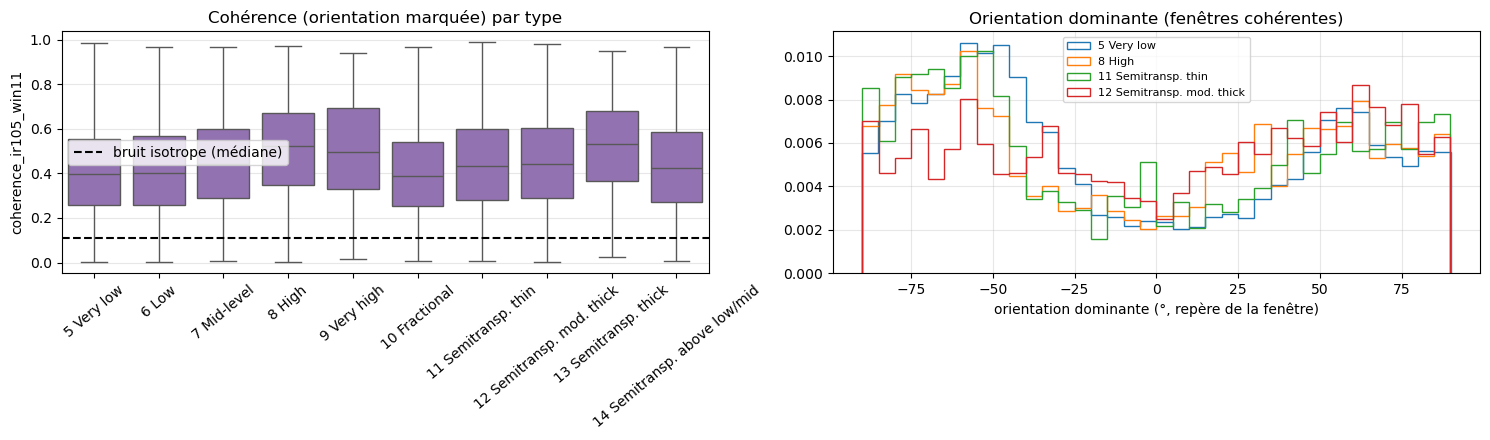

In [30]:
# Anisotropie : cohérence du tenseur de structure (0 = isotrope, 1 = motif orienté)
gi, gj = np.gradient(w105, axis=(1, 2))
Jii, Jjj, Jij = (gi*gi).mean((1, 2)), (gj*gj).mean((1, 2)), (gi*gj).mean((1, 2))
lam_diff = np.sqrt((Jii - Jjj)**2 + 4*Jij**2)
df['coherence_ir105_win11'] = lam_diff / (Jii + Jjj + 1e-9)
df['orientation_ir105_win11_deg'] = np.degrees(0.5 * np.arctan2(2*Jij, Jii - Jjj))
df['grad_ir105_win11'] = np.hypot(gi, gj).mean((1, 2))

# Référence : cohérence d'un bruit blanc isotrope de même taille
rng = np.random.default_rng(0); noise = rng.normal(size=(20000, 11, 11))
ni, nj = np.gradient(noise, axis=(1, 2))
c_noise = np.sqrt(((ni*ni).mean((1,2)) - (nj*nj).mean((1,2)))**2 + 4*(ni*nj).mean((1,2))**2) / ((ni*ni).mean((1,2)) + (nj*nj).mean((1,2)))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
lab = df[CT].map(lambda c: f'{c} {CT_NAMES[c]}')
sns.boxplot(x=lab, y=df['coherence_ir105_win11'], order=[f'{c} {CT_NAMES[c]}' for c in cts], ax=axes[0], color='C4', fliersize=0)
axes[0].axhline(np.median(c_noise), c='k', ls='--', label='bruit isotrope (médiane)')
axes[0].tick_params(axis='x', rotation=40); axes[0].set_xlabel(''); axes[0].legend(); axes[0].set_title('Cohérence (orientation marquée) par type')
for t in [5, 8, 11, 12]:
    m = (df[CT] == t).values & (df['coherence_ir105_win11'].values > 0.5)
    axes[1].hist(df.loc[m, 'orientation_ir105_win11_deg'], bins=36, histtype='step', density=True, label=f'{t} {CT_NAMES[t]}')
axes[1].set_xlabel('orientation dominante (°, repère de la fenêtre)'); axes[1].set_title('Orientation dominante (fenêtres cohérentes)')
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

In [31]:
# Énergie des ondelettes (transformée stationnaire, Haar, 2 niveaux, fenêtre complétée à 12x12)
def swt_energy(win, wavelet='haar', level=2):
    a = np.pad(win, ((0, 0), (0, 1), (0, 1)), mode='reflect')
    a = a - a.mean((1, 2), keepdims=True)
    coeffs = pywt.swt2(a, wavelet, level=level, axes=(1, 2), trim_approx=True)
    out = {}
    for lev, (cH, cV, cD) in zip(range(level, 0, -1), coeffs[1:]):
        out[f'wav_ir105_l{lev}_h'] = (cH**2).mean((1, 2))
        out[f'wav_ir105_l{lev}_v'] = (cV**2).mean((1, 2))
        out[f'wav_ir105_l{lev}_d'] = (cD**2).mean((1, 2))
    return pd.DataFrame(out)

wav = swt_energy(w105)
for c in wav: df[c] = wav[c].values
wl = wav.assign(type=lab.values).groupby('type').median()
wl['l1 total'] = wl[['wav_ir105_l1_h', 'wav_ir105_l1_v', 'wav_ir105_l1_d']].sum(1)
wl['l2 total'] = wl[['wav_ir105_l2_h', 'wav_ir105_l2_v', 'wav_ir105_l2_d']].sum(1)
wl['ratio l2 / l1'] = wl['l2 total'] / wl['l1 total']
display(wl[['l1 total', 'l2 total', 'ratio l2 / l1']].round(3))
print("Spearman avec la cible :")
display(df[list(wav.columns) + ['grad_ir105_win11', 'coherence_ir105_win11']].corrwith(df[TARGET], method='spearman').round(3).to_frame('rho').T)

,l1 total,l2 total,ratio l2 / l1
type,,,
10 Fractional,9.757000,52.581001,5.389
11 Semitransp. thin,24.382999,137.843002,5.653
12 Semitransp. mod. thick,30.285000,175.078003,5.781
13 Semitransp. thick,33.743000,203.315994,6.026
14 Semitransp. above low/mid,42.433998,245.716003,5.791
5 Very low,3.901000,20.750999,5.320
6 Low,3.967000,21.142000,5.330
7 Mid-level,8.451000,45.981998,5.441
8 High,10.105000,58.686001,5.808


Spearman avec la cible :


,wav_ir105_l2_h,wav_ir105_l2_v,wav_ir105_l2_d,wav_ir105_l1_h,wav_ir105_l1_v,wav_ir105_l1_d,grad_ir105_win11,coherence_ir105_win11
rho,0.526,0.521,0.469,0.525,0.517,0.458,0.519,0.11


**À retenir**
- La variabilité augmente nettement avec la taille du voisinage, surtout pour les nuages hauts, semi-transparents et fractionnés : **la grande fenêtre contient de l'information que la 5×5 n'a pas**.
- Le spectre confirme la domination des grandes échelles : **69 à 79 % de la variance à ≈ 10 pixels**, moins de 7 % sous 3 pixels. Les nuages hauts et épais sont les plus lisses, les fractionnés et les très bas les plus « granuleux ». Les filtres de Gabor utiles se situent entre 3 et 6 pixels de longueur d'onde, après retrait du gradient.
- La cohérence (médiane ≈ 0,4) dépasse largement celle d'un bruit blanc (≈ 0,11), mais c'est surtout l'effet du gradient à grande échelle ; elle n'est que faiblement liée à l'altitude (Spearman ≈ 0,11).
- L'**orientation dominante a la même distribution pour tous les types** (pics vers ±60°), y compris les nuages très bas : c'est très probablement un effet de la géométrie de la grille (pixels non carrés en longitude-latitude), pas de la physique. **L'angle n'est pas exploitable** ; seules des mesures invariantes à l'orientation sont à retenir.
- Avec 11 pixels, **2 niveaux d'ondelettes** sont le maximum raisonnable. L'**énergie** des ondelettes est nettement liée à l'altitude (Spearman ≈ 0,5) et distingue les nuages semi-transparents (énergie 6 à 10 fois plus forte que les nuages bas), mais le **rapport entre niveaux varie peu** (5,3 à 6,0) : c'est le niveau de texture, plus que sa répartition entre échelles, qui discrimine.

## 6. Variables physiques dérivées (calculées sur la fenêtre brute)

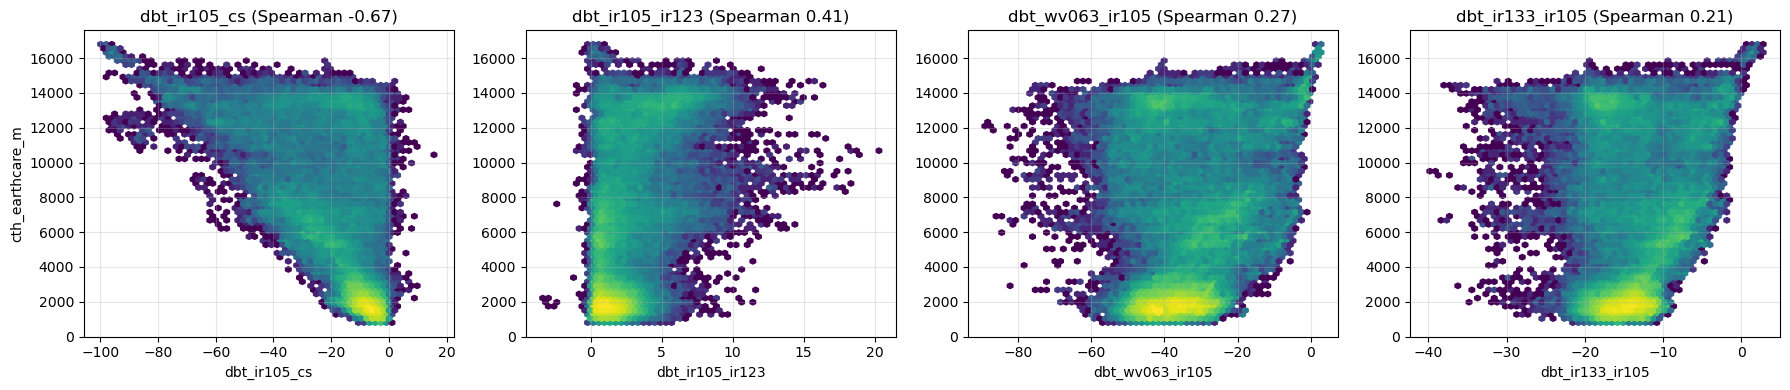

In [32]:
for ci, c in enumerate(CH):
    df[f'bt_{c}_center'] = bt_win11[:, ci, 5, 5]
    df[f'dbt_{c}_cs'] = df[f'bt_{c}_center'] - df[f'bt_{c}_clearsky']
df['dbt_ir105_ir123'] = df['bt_ir105_center'] - df['bt_ir123_center']
df['dbt_wv063_ir105'] = df['bt_wv063_center'] - df['bt_ir105_center']
df['dbt_ir133_ir105'] = df['bt_ir133_center'] - df['bt_ir105_center']

DERIVED = ['dbt_ir105_cs', 'dbt_ir105_ir123', 'dbt_wv063_ir105', 'dbt_ir133_ir105']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, v in zip(axes, DERIVED):
    ax.hexbin(df[v], y, gridsize=60, bins='log', cmap='viridis', mincnt=1)
    ax.set_xlabel(v); ax.set_title(f"{v} (Spearman {df[v].corr(df[TARGET], method='spearman'):.2f})")
axes[0].set_ylabel('cth_earthcare_m'); plt.tight_layout(); plt.show()

In [33]:
# Inversion du profil ERA5 (altitudes des niveaux : atmosphère standard, approximation)
Z_LEVELS = np.array([110, 1460, 3010, 5570, 9160, 11780, 16180], dtype=float)
T = df[[f't_era5_{p}hpa' for p in P_LEVELS]].values

def invert_profile(bt, T):
    out = np.full(len(bt), np.nan)
    done = bt >= T[:, 0]; out[done] = Z_LEVELS[0]
    for lv in range(len(Z_LEVELS) - 1):
        m = ~done & (T[:, lv] >= bt) & (bt > T[:, lv+1])
        out[m] = Z_LEVELS[lv] + (T[m, lv] - bt[m]) / (T[m, lv] - T[m, lv+1]) * (Z_LEVELS[lv+1] - Z_LEVELS[lv])
        done |= m
    out[~done] = Z_LEVELS[np.argmin(T[~done], 1)]
    return out

df['cth_era5inv_m'] = invert_profile(df['bt_ir105_center'].values, T)
pd.DataFrame({'Inversion ERA5 (pixel au sol)': metrics(y, df['cth_era5inv_m'].values),
              'SAFNWC (hors type 10)': metrics(y, df[SAF].values)}).T.round({'N': 0, 'MAE': 0, 'Biais': 0, 'RMSE': 0, 'R2': 3})

,N,MAE,Biais,RMSE,R2
Inversion ERA5 (pixel au sol),87746.0,2475.0,-2132.0,3879.0,0.224
SAFNWC (hors type 10),79433.0,1220.0,-652.0,2158.0,0.764


**À retenir**
- Le **contraste avec le ciel clair** reste la variable dérivée la plus liée à l'altitude ; le split-window sépare les cirrus semi-transparents.
- L'inversion physique naïve est très biaisée (nuages placés trop bas) : utile au mieux comme variable d'appoint.

## 7. Valeur informative des familles de variables (validation croisée par jour)

Même modèle (gradient boosting LightGBM, perte MAE) et mêmes jours, en ajoutant les familles une par une.
**Validation croisée en 13 plis : chaque jour sert une fois de test.** Les nuages de type 10 sont gardés.

> Cellule la plus longue du notebook (≈ 10 min sur 2 cœurs). Mettre `RUN_CV = False` pour la sauter.

In [36]:
RUN_CV = True
try:
    import lightgbm as lgb
except ImportError:
    RUN_CV = False; print('lightgbm non installé : section sautée (pip install lightgbm)')

# Statistiques sur la fenêtre brute (5x5 et 11x11), tous canaux
for ci, c in enumerate(CH):
    p5 = bt_win11[:, ci, 3:8, 3:8].reshape(N, 25); p11 = bt_win11[:, ci].reshape(N, 121)
    df[f'bt_{c}_min_p5raw'], df[f'bt_{c}_max_p5raw'], df[f'bt_{c}_std_p5raw'] = p5.min(1), p5.max(1), p5.std(1)
    df[f'bt_{c}_min_win11'], df[f'bt_{c}_max_win11'] = p11.min(1), p11.max(1)
    df[f'bt_{c}_std_win11'], df[f'bt_{c}_q10_win11'] = p11.std(1), np.quantile(p11, .1, axis=1)

BASE = [f'bt_{c}_center' for c in CH] + [f'bt_{c}_clearsky' for c in CH] + [f't_era5_{p}hpa' for p in P_LEVELS]
FAMILIES = {
    'A. centre + ciel clair + ERA5': BASE,
    'B. A + stats 5×5 corrigée (FUITE)': BASE + [f'bt_{c}_{s}_p5corr' for c in CH for s in ['min', 'max', 'std']],
    'C. A + stats 5×5 brute': BASE + [f'bt_{c}_{s}_p5raw' for c in CH for s in ['min', 'max', 'std']],
    'D. C + stats 11×11 brute': BASE + [f'bt_{c}_{s}_p5raw' for c in CH for s in ['min', 'max', 'std']]
                                + [f'bt_{c}_{s}_win11' for c in CH for s in ['min', 'max', 'std', 'q10']],
}
FAMILIES['E. D + physique + texture'] = FAMILIES['D. C + stats 11×11 brute'] + DERIVED[1:] + [f'dbt_{c}_cs' for c in CH] \
    + ['cth_era5inv_m', 'grad_ir105_win11', 'coherence_ir105_win11'] + list(wav.columns)

# Interdits en opérationnel : vérification automatique (règle du dictionnaire)
FORBIDDEN = ('p5corr', 'parallax_shift', 'earthcare')
for name, feats in FAMILIES.items():
    bad = [f for f in feats if any(t in f for t in FORBIDDEN)]
    print(f'{name:38s} {len(feats):3d} variables', '| interdites :', len(bad))

A. centre + ciel clair + ERA5           19 variables | interdites : 0
B. A + stats 5×5 corrigée (FUITE)       37 variables | interdites : 18
C. A + stats 5×5 brute                  37 variables | interdites : 0
D. C + stats 11×11 brute                61 variables | interdites : 0
E. D + physique + texture               79 variables | interdites : 0


In [37]:
if RUN_CV:
    prm = dict(objective='l1', n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=50,
               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=-1)
    res, preds = [], {}
    for name, feats in FAMILIES.items():
        X = df[feats].values.astype('float32'); p = np.zeros(N)
        for d in dates:
            te = (df['date_utc'] == d).values
            p[te] = lgb.LGBMRegressor(**prm).fit(X[~te], y[~te]).predict(X[te])
        preds[name] = p
        day_mae = pd.Series(np.abs(p - y)).groupby(df['date_utc'].values).mean()
        res.append({'famille': name, 'MAE (m)': np.abs(p - y).mean(), 'écart-type entre jours (m)': day_mae.std(),
                    'biais (m)': (p - y).mean(), 'MAE > 8 km': np.abs(p - y)[y > 8000].mean(),
                    'MAE semi-transp. (11–14)': np.abs(p - y)[df[CT].between(11, 14).values].mean()})
    cv_res = pd.DataFrame(res).set_index('famille').round(0)
    saf_ok = ~df[SAF].isna().values
    print(f"SAFNWC (hors type 10) : MAE {np.abs(df[SAF].values[saf_ok] - y[saf_ok]).mean():.0f} m")
    display(cv_res)

/home/kossi/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/kossi/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/kossi/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/kossi/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/home/kossi/.config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/skle

SAFNWC (hors type 10) : MAE 1220 m


,MAE (m),écart-type entre jours (m),biais (m),MAE > 8 km,MAE semi-transp. (11–14)
famille,,,,,
A. centre + ciel clair + ERA5,1007.0,106.0,-147.0,1739.0,1416.0
B. A + stats 5×5 corrigée (FUITE),728.0,87.0,-63.0,1173.0,912.0
C. A + stats 5×5 brute,772.0,87.0,-65.0,1236.0,988.0
D. C + stats 11×11 brute,762.0,89.0,-51.0,1192.0,958.0
E. D + physique + texture,736.0,89.0,-62.0,1193.0,896.0


,A centre seul,D + stats 11×11,E + physique/texture,SAFNWC,N
type,,,,,
10 Fractional,1675.0,1232.0,1220.0,NaN,8313
11 Semitransp. thin,2493.0,1332.0,1232.0,1951.0,4197
12 Semitransp. mod. thick,1126.0,888.0,805.0,1392.0,8249
13 Semitransp. thick,663.0,571.0,557.0,959.0,1755
14 Semitransp. above low/mid,1167.0,863.0,874.0,1431.0,3258
5 Very low,688.0,520.0,499.0,887.0,30694
6 Low,1080.0,878.0,861.0,1516.0,16278
7 Mid-level,844.0,708.0,688.0,1359.0,8113
8 High,579.0,515.0,525.0,1222.0,6072


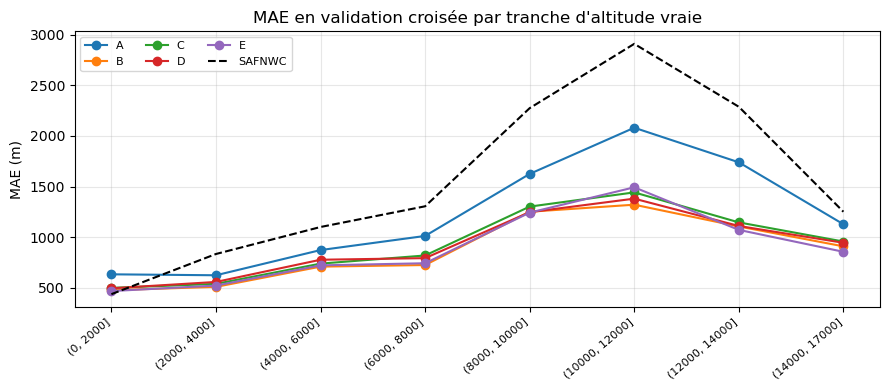

In [38]:
if RUN_CV:
    best = list(FAMILIES)[-1]
    t = pd.DataFrame({'type': df[CT].map(lambda c: f'{c} {CT_NAMES[c]}'),
                      'A': np.abs(preds[list(FAMILIES)[0]] - y), 'D': np.abs(preds['D. C + stats 11×11 brute'] - y),
                      'E': np.abs(preds[best] - y), 'SAFNWC': np.abs(df[SAF].values - y)})
    tab = t.groupby('type').mean().round(0); tab['N'] = t.groupby('type').size()
    tab.columns = ['A centre seul', 'D + stats 11×11', 'E + physique/texture', 'SAFNWC', 'N']
    display(tab)

    fig, ax = plt.subplots(figsize=(9, 4))
    gb = pd.DataFrame({k[:1]: np.abs(v - y) for k, v in preds.items()}).groupby(df['alt_bin'].values, observed=True).mean()
    for c in gb: ax.plot(range(len(gb)), gb[c].values, 'o-', label=c)
    ax.plot(range(len(gb)), pd.Series(np.abs(df[SAF].values - y)).groupby(df['alt_bin'].values, observed=True).mean().values, 'k--', label='SAFNWC')
    ax.set_xticks(range(len(gb)), [str(b) for b in gb.index], rotation=40, ha='right', fontsize=8)
    ax.set_ylabel('MAE (m)'); ax.set_title("MAE en validation croisée par tranche d'altitude vraie"); ax.legend(ncol=3, fontsize=8)
    plt.tight_layout(); plt.show()

In [39]:
if RUN_CV:
    # Comparaison appariée jour par jour : l'écart entre deux familles, mesuré sur les mêmes jours
    names = list(FAMILIES)
    day = df['date_utc'].values
    mae_day = pd.DataFrame({n[:1]: pd.Series(np.abs(preds[n] - y)).groupby(day).mean() for n in names})
    pairs = [('A', 'C', 'apport des stats 5×5 brutes'), ('C', 'B', 'coût de la fuite (C − B)'),
             ('C', 'D', 'apport de la 11×11'), ('D', 'E', 'apport physique + texture'), ('B', 'E', 'E rattrape-t-il la fuite ? (B − E)')]
    rows = []
    for a, b, lab in pairs:
        diff = mae_day[a] - mae_day[b]
        rows.append({'comparaison': f'{a} → {b} : {lab}', 'gain moyen (m)': diff.mean(), 'écart-type (m)': diff.std(),
                     'jours où le gain est positif': f"{(diff > 0).sum()} / {len(diff)}"})
    display(pd.DataFrame(rows).set_index('comparaison').round(0))

,gain moyen (m),écart-type (m),jours où le gain est positif
comparaison,,,
A → C : apport des stats 5×5 brutes,234.0,60.0,13 / 13
C → B : coût de la fuite (C − B),46.0,24.0,13 / 13
C → D : apport de la 11×11,10.0,26.0,7 / 13
D → E : apport physique + texture,22.0,28.0,12 / 13
B → E : E rattrape-t-il la fuite ? (B − E),-13.0,38.0,5 / 13


**À retenir (section 7)**

Validation croisée en 13 plis par jour, gradient boosting, nuages de type 10 inclus. Référence SAFNWC : 1 220 m (hors type 10).

| Famille | MAE | Lecture |
|---|---|---|
| A. centre + ciel clair + ERA5 | 1 007 m | Le pixel au sol seul ne suffit pas |
| B. + stats 5×5 corrigée (**fuite**) | 728 m | Meilleur score, mais impossible en opérationnel |
| C. + stats 5×5 brute | 772 m | Le voisinage brut apporte beaucoup : −234 m par rapport à A, **13 jours sur 13** |
| D. + stats 11×11 brute | 762 m | Gain faible et instable (−10 m, 7 jours sur 13) |
| E. + physique + texture | 736 m | Gain net (−22 m, **12 jours sur 13**), surtout sur les semi-transparents (958 → 896 m) |

- **La fuite coûte 46 m, de façon très régulière (13 jours sur 13).** Avec des statistiques simples, la grande fenêtre ne la compense **pas** : le résultat obtenu auparavant sur le seul jour de test était trompeur.
- Les variables physiques et de texture (contrastes, split-window, gradient, ondelettes) réduisent l'écart à **13 m** de la version avec fuite, sans l'annuler (E fait mieux que B seulement 5 jours sur 13).
- Les gains se concentrent sur les **semi-transparents et les nuages entre 8 et 12 km**, là où le SAFNWC est le plus mauvais. Exception : les nuages très hauts (type 9, 817 pixels), où toutes les familles font moins bien que le SAFNWC (≈ 870 contre 707 m).
- Écart-type de la MAE entre jours : ≈ 90 m. Les écarts entre familles doivent donc être jugés **jour par jour** (tableau apparié), pas sur les moyennes.
- Ces chiffres viennent du gradient boosting ; le MLP de référence faisait mieux sur l'ancien jeu. Ils servent à **comparer des familles de variables**, pas à fixer la performance finale.

## 8. Diagnostic de la référence SAFNWC (hors type 10)

In [40]:
e = df[SAF] - df[TARGET]
diag = pd.DataFrame({'N': df.groupby(CT)[SAF].count(), 'MAE': e.abs().groupby(df[CT]).mean(),
                     'Biais': e.groupby(df[CT]).mean(), '> 3 km (%)': 100 * (e.abs() > 3000).groupby(df[CT]).mean()})
diag.index = [f'{i} {CT_NAMES[i]}' for i in diag.index]
display(diag.round(0))
print('Global :', metrics(y, df[SAF].values).round(3).to_dict())

,N,MAE,Biais,> 3 km (%)
5 Very low,30694,887.0,-564.0,4.0
6 Low,16278,1516.0,-1365.0,16.0
7 Mid-level,8113,1359.0,-1266.0,14.0
8 High,6072,1222.0,-1069.0,4.0
9 Very high,817,707.0,-614.0,0.0
10 Fractional,0,NaN,NaN,0.0
11 Semitransp. thin,4197,1951.0,1018.0,19.0
12 Semitransp. mod. thick,8249,1392.0,51.0,10.0
13 Semitransp. thick,1755,959.0,-357.0,2.0
14 Semitransp. above low/mid,3258,1431.0,294.0,12.0


Global : {'N': 79433.0, 'MAE': 1220.225, 'Biais': -651.723, 'RMSE': 2157.518, 'R2': 0.764}


## 9. Synthèse et conséquences pour la modélisation

| Constat | Conséquence |
|---|---|
| `_p5corr` et `parallax_shift_*` calculés avec la cible | Exclus du scénario opérationnel ; vérification automatique dans le code |
| SAFNWC = 63 535 pour les 8 313 nuages de type 10 | NaN ; type 10 gardé pour l'apprentissage, exclu des comparaisons avec le SAFNWC |
| Décalage de parallaxe de 2 à 3 pixels au-dessus de 5 km, avec une direction privilégiée | Le modèle doit chercher le nuage dans le voisinage ; prudence avec les rotations et retournements en augmentation de données |
| Fuite = 46 m en validation croisée, non compensée par des statistiques simples sur la 11×11 | Il faut des descripteurs spatiaux plus fins (texture, forme, position) ou un CNN capable de localiser le nuage |
| Champ dominé par un gradient à grande échelle ; pixel le plus froid sur les bords | Retirer le gradient (plan ajusté) avant Gabor et ondelettes ; se méfier de `min_win11` |
| Variance surtout à ≈ 10 px, moins de 7 % sous 3 px | Gabor entre 3 et 6 px de longueur d'onde ; 2 niveaux d'ondelettes au plus |
| Orientation dominante identique pour tous les types (artefact probable de la grille) | Uniquement des descripteurs invariants à l'orientation (énergies moyennées sur les angles, scattering) |
| Physique + texture : −22 m, 12 jours sur 13, surtout sur les semi-transparents | Piste confirmée : à approfondir avec Gabor, scattering et CNN |
| Écart-type entre jours ≈ 90 m | Toujours comparer les modèles jour par jour, sur les mêmes plis |

**Base de comparaison pour la suite** (scénario opérationnel, validation croisée par jour, gradient boosting) : famille E, **MAE 736 m**, contre 728 m avec la fuite et 1 220 m pour le SAFNWC.
